C:\Users\Rujuta\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(


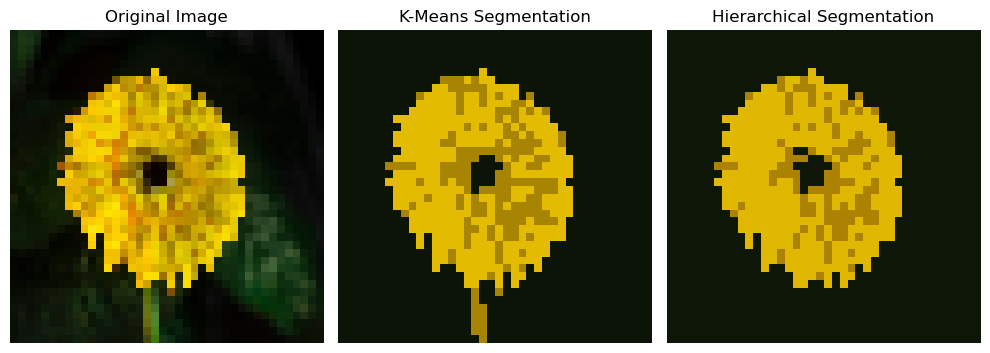

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, AgglomerativeClustering

# Step 1: Read the image
img = cv2.imread(r"C:\Users\Rujuta\Downloads\flower.jpg")

if img is None:
    print("Error: Image not found. Keep image.jpg in the same folder.")
else:
    # Step 2: Convert BGR to RGB and resize
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (40, 40))

    # Step 3: Convert image pixels into data points
    pixels = img.reshape(-1, 3)

    # Step 4: Apply K-Means clustering
    kmeans = KMeans(n_clusters=3, random_state=0, n_init=10)
    kmeans_labels = kmeans.fit_predict(pixels)

    kmeans_img = kmeans.cluster_centers_[
        kmeans_labels
    ].reshape(img.shape).astype(np.uint8)

    # Step 5: Apply Hierarchical clustering
    hc = AgglomerativeClustering(n_clusters=3)
    hc_labels = hc.fit_predict(pixels)

    # Calculate average color of each cluster
    hc_img = np.zeros_like(pixels)

    for i in range(3):
        points = pixels[hc_labels == i]
        hc_img[hc_labels == i] = points.mean(axis=0)

    hc_img = hc_img.reshape(img.shape).astype(np.uint8)

    # Step 6: Display the results
    plt.figure(figsize=(10, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(img)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(kmeans_img)
    plt.title("K-Means Segmentation")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(hc_img)
    plt.title("Hierarchical Segmentation")
    plt.axis("off")

    plt.tight_layout()
    plt.show()